<a href="https://colab.research.google.com/github/husn44/bnpl-default-prediction/blob/iman-branch/notebooks/03_eda_preprocessing_C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**EDA Preprocessing**

In [2]:
# Import dataset
import pandas as pd
df = pd.read_csv("raw_bnpl.csv")
df.head()

,customer_id,age,gender,state,employment_type,monthly_income,credit_score,existing_monthly_debt,debt_to_income,num_credit_cards,...,num_instalments,instalment_amount,purchase_hour,is_promo_period,months_as_customer,past_late_payments,app_logins_per_week,_stress_hint,_impulse_hint,default_flag
0,C00001,31,Female,Selangor,Full-time,3872.78,617.0,1229.30,0.322,0,...,3,16.67,2,0,18,0,5,high,high,0
1,C00002,21,Female,Selangor,Student,600.00,558.0,55.45,0.554,1,...,3,277.25,16,0,15,0,3,high,low,0
2,C00003,35,Female,Selangor,Gig worker,2708.93,772.0,1099.96,0.420,3,...,3,37.18,11,0,34,0,2,high,low,0
3,C00004,37,Female,Sarawak,Gig worker,2594.50,594.0,525.14,0.212,2,...,3,25.66,17,0,4,0,0,low,low,0
4,C00005,18,Female,Penang,Full-time,2478.81,579.0,473.67,0.198,0,...,3,16.67,21,0,13,1,0,high,low,0


In [3]:
# Description of dataset
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            3000 non-null   object 
 1   age                    3000 non-null   int64  
 2   gender                 3000 non-null   object 
 3   state                  3000 non-null   object 
 4   employment_type        2970 non-null   object 
 5   monthly_income         2940 non-null   float64
 6   credit_score           2910 non-null   float64
 7   existing_monthly_debt  3000 non-null   float64
 8   debt_to_income         3000 non-null   float64
 9   num_credit_cards       3000 non-null   int64  
 10  num_active_bnpl_plans  3000 non-null   int64  
 11  bnpl_provider          3000 non-null   object 
 12  merchant_category      3000 non-null   object 
 13  purchase_amount        3000 non-null   float64
 14  num_instalments        3000 non-null   int64  
 15  inst

,age,monthly_income,credit_score,existing_monthly_debt,debt_to_income,num_credit_cards,num_active_bnpl_plans,purchase_amount,num_instalments,instalment_amount,purchase_hour,is_promo_period,months_as_customer,past_late_payments,app_logins_per_week,default_flag
count,3000.000000,2940.000000,2910.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.0000
mean,29.161333,4214.190020,643.481443,1054.997807,0.298727,1.328333,1.521000,722.903607,5.104000,143.140853,13.75200,0.247000,24.585667,0.901333,4.654000,0.2030
std,7.406816,2868.496218,77.010967,1262.567452,0.211305,1.256605,1.476805,855.862849,3.020633,164.666578,5.77676,0.431339,13.929537,1.425111,3.606192,0.4023
min,18.000000,600.000000,351.000000,1.910000,0.013000,0.000000,0.000000,50.000000,3.000000,4.170000,0.00000,0.000000,1.000000,0.000000,0.000000,0.0000
25%,23.000000,2103.367500,593.250000,285.587500,0.147000,0.000000,0.000000,149.367500,3.000000,41.115000,10.00000,0.000000,12.000000,0.000000,2.000000,0.0000
50%,29.000000,3643.910000,646.000000,641.510000,0.244000,1.000000,1.000000,318.835000,3.000000,78.125000,14.00000,0.000000,25.000000,0.000000,4.000000,0.0000
75%,34.000000,5628.892500,696.000000,1348.295000,0.397250,2.000000,2.000000,1093.782500,6.000000,187.695000,18.00000,0.000000,37.000000,1.000000,7.000000,0.0000
max,54.000000,20027.350000,850.000000,16508.390000,2.052000,5.000000,8.000000,6000.000000,12.000000,1790.620000,23.00000,1.000000,48.000000,10.000000,24.000000,1.0000


In [4]:
# Check for missing values
df.isnull().sum()

,0
customer_id,0
age,0
gender,0
state,0
employment_type,30
monthly_income,60
credit_score,90
existing_monthly_debt,0
debt_to_income,0
num_credit_cards,0


Employment type : 30 missing values  
Monthly income : 60 missing values  
Credit score : 90 missing values

In [5]:
# Check for default rate (target distribution)
df["default_flag"].value_counts(normalize=True)

,proportion
default_flag,
0,0.797
1,0.203


The target variable *default_flag* is moderately imbalanced, with 20.3% of customers defaulting and 79.7% not defaulting.   
Because a naive majority-class model would achieve 79.7% accuracy, models were evaluated primarily on F1-score and ROC-AUC, and SMOTE was applied to the training set to address the imbalance.



<Axes: title={'center': 'Default vs Non-default'}, xlabel='default_flag'>

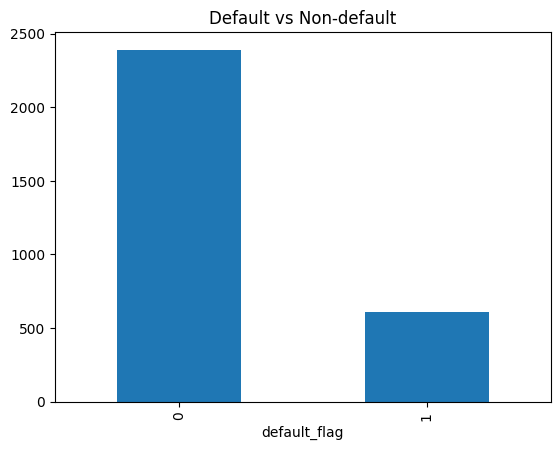

In [6]:
# Bar Chart of Default vs Non-default
df["default_flag"].value_counts().plot(kind="bar", title="Default vs Non-default")